In [1]:
import warnings
warnings.filterwarnings("ignore")


Целью данной работы является предсказание площади, которая окажется выгоревшей в результате лесных пожаров в северо-восточном регионе Португалии, т.е. мы имеем дело с задачей регрессии

In [2]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.4 MB/s eta 0:00:00


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import torch
import torch.nn as nn
from tqdm.notebook import tqdm
import math

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor
from sklearn.svm import SVR
from scipy import stats

from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.manifold import TSNE
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import r2_score, precision_score, recall_score, f1_score,accuracy_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, classification_report
from sklearn.model_selection import cross_val_score, train_test_split, ParameterGrid, KFold, GridSearchCV

# EDA

In [4]:
dataset = pd.read_csv('/content/drive/MyDrive/forestfires.csv')

Проведем описание всех переменных, взятое из документации UCI:
1) X - Пространственная координата по оси x на карте парка Монтезинью: от 1 до 9.
2) Y - Пространственная координата по оси x на карте парка Монтезинью: от 2 до 9.
3) индекс FFMC: от 0,0 до 100,0 -- Численный показатель содержания влаги в мелком опаде и в других твердых мелких в горючих материалах, этот код указывает на относительную легкость зажигания и воспламеняемости мелких горючих материалов.
4) индекс DMC: 1,1 до 300,0 -- Численный показатель среднего содержания влаги неуплотненной органической подстилки на средней глубине, этот код обозначает величину сгорающего горючего материала и древесных материалов среднего размера в средних слоях подстилки.
5) индекс DC: от 7,9 до 890,0 -- Численный показатель среднего содержания влаги в глубокой, уплотненной органической подстилке. Этот код указывает на сезонное воздействие засухи на ЛГМ и величину тления в глубокой подстилке и больших бревнах.
6) индекс ISI: от 0,0 до 60,0 -- Численный показатель ожидаемой скорости распространения пожара. Он объединяет влияния ветра и КВМ ЛГМ на скорость распространения, но исключает влияние изменяющегося количества горючих материалов.
7) temp: температура в градусах Цельсия: от 2.2 до 33.
8) RH: относительная влажность воздуха в %: от 15,0 до 100
9) wind – скорость ветра в км/ч: от 0,4 до 9.4.
10) дождь в мм/м2 : от 0,0 до 6.4.
11) SA – солнечная радиация в кВч/м2: от 1,0 до 6.4
12) площадь сгоревшего участка местности (в га): от 0,00 до 1090,0.

In [5]:
dataset.head()

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


In [6]:
dataset.describe()

,X,Y,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
count,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000
mean,4.669246,4.299807,90.644681,110.872340,547.940039,9.021663,18.889168,44.288201,4.017602,0.021663,12.847292
std,2.313778,1.229900,5.520111,64.046482,248.066192,4.559477,5.806625,16.317469,1.791653,0.295959,63.655818
min,1.000000,2.000000,18.700000,1.100000,7.900000,0.000000,2.200000,15.000000,0.400000,0.000000,0.000000
25%,3.000000,4.000000,90.200000,68.600000,437.700000,6.500000,15.500000,33.000000,2.700000,0.000000,0.000000
50%,4.000000,4.000000,91.600000,108.300000,664.200000,8.400000,19.300000,42.000000,4.000000,0.000000,0.520000
75%,7.000000,5.000000,92.900000,142.400000,713.900000,10.800000,22.800000,53.000000,4.900000,0.000000,6.570000
max,9.000000,9.000000,96.200000,291.300000,860.600000,56.100000,33.300000,100.000000,9.400000,6.400000,1090.840000


У нас имеется 2 категориальных признака: месяц и день недели. Для признаков такого рода является оптимальным использовать циклическое кодирование:

$$
u \to \left[ \sin\left(\frac{2\pi \cdot u}{\max(u)}\right); \cos\left(\frac{2\pi \cdot u}{\max(u)}\right) \right]
$$

где u означает значение некоторого признака, а max(u) -- максимальное значение, которое он может принимать, например 12 для месяцев.
Однако, мы оставим и исходный dataset, так как для работы с категориальными признаками мы сможем использовать различные бустинги и случайный лес. Кодирование же нам нужно будет, чтобы спокойно использовать линейную регрессию и другие методы, которые не умеют работать с категориальными признаками.


Заменим сначала названия месяцев и дней недели на их порядковый номер

In [7]:
print(*dataset['month'].unique())
print(*dataset['day'].unique())

mar oct aug sep apr jun jul feb jan dec may nov
fri tue sat sun mon wed thu


In [8]:
data = dataset.copy()
numpy_months = (data['month'] == 'mar').to_numpy()
mapping = {'jan': 1, 'feb' : 2, 'mar' : 3, 'apr' : 4, 'may' : 5, 'jun' : 6,
           'jul' : 7, 'aug' : 8, 'sep' : 9, 'oct' :10, 'nov' : 11, 'dec' : 12}
ser = (data['month'].map(mapping))
data['month'] = ser
mapping = {'mon':1, 'tue':2, 'wed':3, 'thu':4, 'fri' :5, 'sat':6, 'sun':7}
ser = data['day'].map(mapping)
data['day'] = ser
data

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,3,5,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.00
1,7,4,10,2,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.00
2,7,4,10,6,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.00
3,8,6,3,5,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.00
4,8,6,3,7,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
512,4,3,8,7,81.6,56.7,665.6,1.9,27.8,32,2.7,0.0,6.44
513,2,4,8,7,81.6,56.7,665.6,1.9,21.9,71,5.8,0.0,54.29
514,7,4,8,7,81.6,56.7,665.6,1.9,21.2,70,6.7,0.0,11.16
515,1,4,8,6,94.4,146.0,614.7,11.3,25.6,42,4.0,0.0,0.00


In [9]:
ser = data['month']
ser_sin = np.sin(2*np.pi*(ser.to_numpy())/12)
data.insert(loc = 3, column = 'month_sin', value = ser_sin)
ser_cos = np.cos(2*np.pi*(ser.to_numpy())/12)
data.insert(loc = 4, column = 'month_cos', value = ser_cos)


In [10]:
ser = data['day']
ser_sin = np.sin(2*np.pi*(ser.to_numpy())/12)
data.insert(loc = 5, column = 'day_sin', value = ser_sin)
ser_cos = np.cos(2*np.pi*(ser.to_numpy())/12)
data.insert(loc = 6, column = 'day_cos', value = ser_cos)


Удалим теперь старые переменные


In [11]:
data.drop(labels=['month', 'day'], axis =1, inplace = True)

In [12]:
data

,X,Y,month_sin,month_cos,day_sin,day_cos,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,1.000000,6.123234e-17,5.000000e-01,-0.866025,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.00
1,7,4,-0.866025,5.000000e-01,8.660254e-01,0.500000,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.00
2,7,4,-0.866025,5.000000e-01,1.224647e-16,-1.000000,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.00
3,8,6,1.000000,6.123234e-17,5.000000e-01,-0.866025,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.00
4,8,6,1.000000,6.123234e-17,-5.000000e-01,-0.866025,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
512,4,3,-0.866025,-5.000000e-01,-5.000000e-01,-0.866025,81.6,56.7,665.6,1.9,27.8,32,2.7,0.0,6.44
513,2,4,-0.866025,-5.000000e-01,-5.000000e-01,-0.866025,81.6,56.7,665.6,1.9,21.9,71,5.8,0.0,54.29
514,7,4,-0.866025,-5.000000e-01,-5.000000e-01,-0.866025,81.6,56.7,665.6,1.9,21.2,70,6.7,0.0,11.16
515,1,4,-0.866025,-5.000000e-01,1.224647e-16,-1.000000,94.4,146.0,614.7,11.3,25.6,42,4.0,0.0,0.00


Давайте теперь построи м матрицу корреляций

In [13]:
corr_matrix = data.corr()
(corr_matrix['area'][:-1]).sort_values(ascending=False)

,area
temp,0.097844
DMC,0.072994
X,0.063385
DC,0.049383
Y,0.044873
FFMC,0.040122
wind,0.012317
ISI,0.008258
month_cos,-0.001847
rain,-0.007366


Видим, что сильной корреляции между area и каким-либо признаком не обнаруживается.

Но для того, чтобы убедиться в этом наверняка строим heatmap для матрицы корреляций.

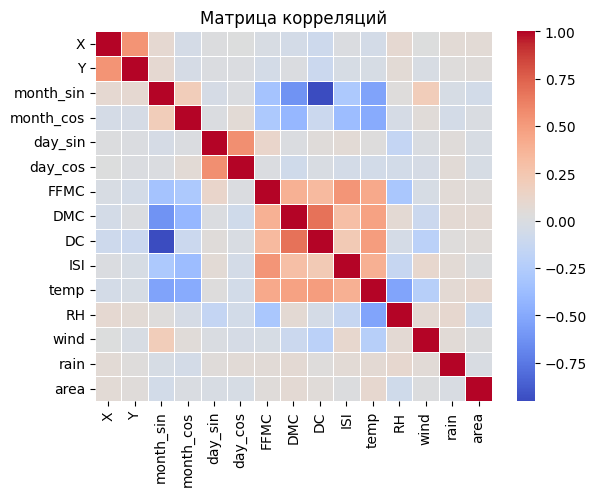

In [14]:
sns.heatmap(corr_matrix,
            cmap='coolwarm',
            linewidths=0.5,
            cbar=True)

plt.title('Матрица корреляций')
plt.show()

Из тепловой карты видно, что, действительно, с площадью возгорания ничего в особенности не коррелирует. Однако, в целом, есть скоррелированные признаки. Из очевидной корреляции month_cos и month_sin. Ну это и понятно, ведь они порождены одним признаком. Но есть и менее очевидные корреляции. Это наталкивает на мысль, что можно пробовать применять метод главных компонент для редцирования размерности пространства признаков.

Поскольку в данных есть некоторое количество выбросов, то мы установим лимиты по оси y -- то есть ограничим area.

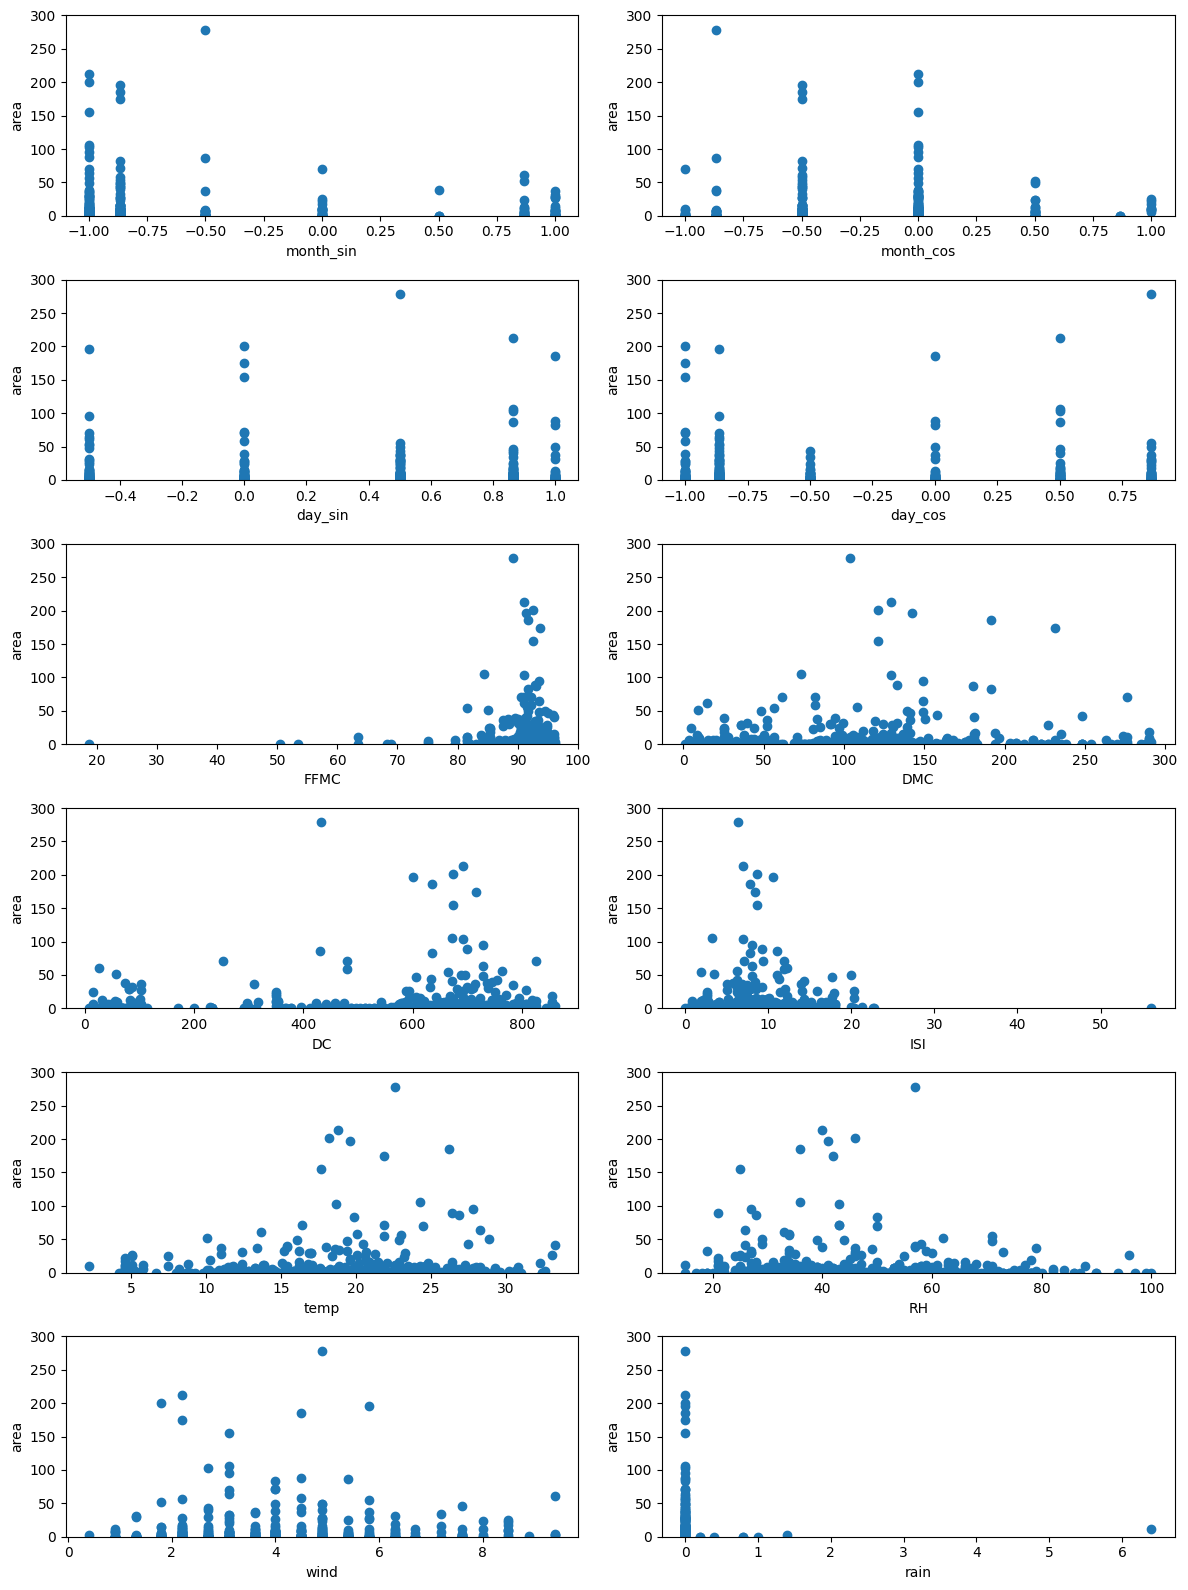

In [15]:
fig, axes = plt.subplots(6, 2, figsize = (12,16))
feat = (data.columns[:-1].to_numpy())[2:14]
for i, ax in enumerate(axes.ravel()):
  ax.scatter(data=data, x = feat[i], y ='area')

  ax.set_xlabel(feat[i])
  ax.set_ylabel('area')
  ax.set_ylim(0,300)
plt.tight_layout()
plt.show()

Видим, что также есть выброс по rain. Уберем и его


In [16]:
data_filtered = data[data['area'] <=300]
data_filtered = data_filtered[data_filtered['rain'] <=3]
data_filtered.describe()

,X,Y,month_sin,month_cos,day_sin,day_cos,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
count,514.000000,514.000000,514.000000,5.140000e+02,5.140000e+02,514.000000,514.000000,514.000000,514.000000,514.000000,514.000000,514.000000,514.000000,514.000000,514.000000
mean,4.655642,4.293774,-0.538895,-2.195463e-01,3.745547e-01,-0.337157,90.622374,110.498833,547.161089,9.002724,18.843969,44.319066,4.014202,0.009339,9.327062
std,2.312795,1.230414,0.704317,4.081884e-01,5.179814e-01,0.692231,5.527291,63.966678,248.578068,4.561688,5.792616,16.308531,1.796035,0.092982,27.377201
min,1.000000,2.000000,-1.000000,-1.000000e+00,-5.000000e-01,-1.000000,18.700000,1.100000,7.900000,0.000000,2.200000,15.000000,0.400000,0.000000,0.000000
25%,3.000000,4.000000,-1.000000,-5.000000e-01,1.224647e-16,-0.866025,90.200000,63.875000,434.400000,6.425000,15.500000,33.000000,2.700000,0.000000,0.000000
50%,4.000000,4.000000,-0.866025,-1.836970e-16,5.000000e-01,-0.866025,91.600000,108.300000,661.800000,8.400000,19.300000,42.000000,4.000000,0.000000,0.495000
75%,7.000000,5.000000,-0.500000,-1.836970e-16,8.660254e-01,0.500000,92.900000,141.300000,713.900000,10.700000,22.775000,53.000000,4.900000,0.000000,6.437500
max,9.000000,9.000000,1.000000,1.000000e+00,1.000000e+00,0.866025,96.200000,291.300000,860.600000,56.100000,33.300000,100.000000,9.400000,1.400000,278.530000


Теперь, когда удалены выбросы, приведем данные к стандратному виду, используя StandardScaler

In [17]:
X = data_filtered.drop(['area'], axis=1)
y = data_filtered['area']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, shuffle=True, random_state = 42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Теперь, как и обещалось выше, применим метод главных компонент.

In [18]:
pca = PCA()
pca.fit(X_train)

# Смотрим объяснённую дисперсию
explained_variance_ratio = pca.explained_variance_ratio_
cumsum = np.cumsum(explained_variance_ratio)

print("Доля дисперсии на каждой компоненте:", explained_variance_ratio)
print("Накопленная доля дисперсии:", cumsum)

Доля дисперсии на каждой компоненте: [0.2656989  0.12525689 0.1138647  0.10284177 0.09015854 0.06277771
 0.06018279 0.04960611 0.03451088 0.03209433 0.02880473 0.02206285
 0.00983527 0.00230454]
Накопленная доля дисперсии: [0.2656989  0.39095578 0.50482048 0.60766225 0.69782079 0.7605985
 0.82078129 0.8703874  0.90489828 0.93699262 0.96579734 0.98786019
 0.99769546 1.        ]


Визуализируем полученный результат


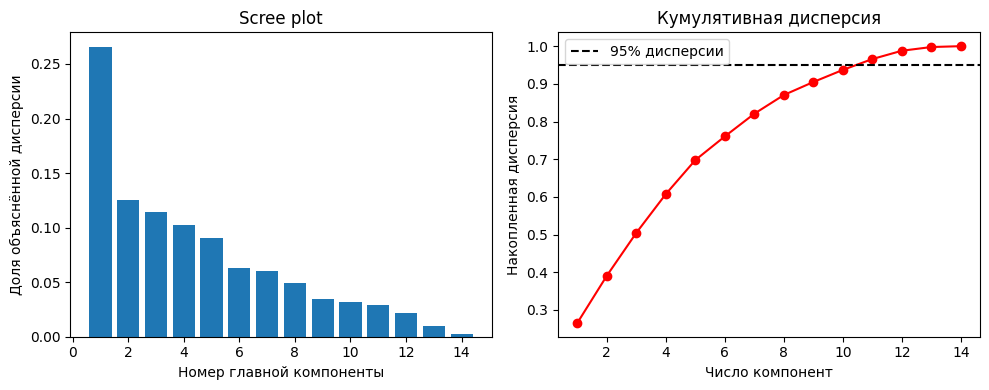

In [19]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.bar(range(1, len(pca.explained_variance_ratio_)+1), pca.explained_variance_ratio_)
plt.xlabel('Номер главной компоненты')
plt.ylabel('Доля объяснённой дисперсии')
plt.title('Scree plot')

plt.subplot(1, 2, 2)
plt.plot(range(1, len(cumsum)+1), cumsum, 'ro-')
plt.xlabel('Число компонент')
plt.ylabel('Накопленная дисперсия')
plt.title('Кумулятивная дисперсия')
plt.axhline(y=0.95, color='k', linestyle='--', label='95% дисперсии')
plt.legend()
plt.tight_layout()
plt.show()

На деле оказывается, что смысла делать метод главных компонент никакого нет, поэтому откажемся от этой идеи.  

Для борьбы с мультиколлинеарностью, которая естественным образом возникает, когда мы говорим о FFMC и DMC (оба эти признака характеризует влажность), мы просто будет использовать L1 регуряризацию, чтобы занулить один из признаков.

Кластеризуем наши данные. Это может быть очень полезно для задачи регрессии, так как если получится выделить "хорошую" кластерную структуру, то мы сможем строить регрессию для каждого кластера отдельно, поэтому кластеризация может оказаеться очень полезной в нашем случае.

Метод, которые применим -- это DBSCAN.

In [20]:
dbscan = DBSCAN(eps=2.5, min_samples=5)
labels_db = dbscan.fit_predict(X_train)

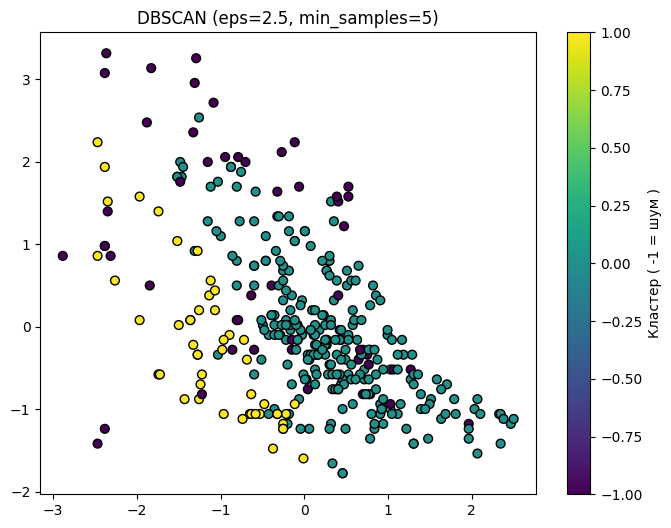

In [21]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_train[:, 10], X_train[:, 11],
                      c=labels_db, cmap='viridis', s=40, edgecolors='k')
plt.title(f'DBSCAN (eps=2.5, min_samples=5)')
plt.colorbar(scatter, label='Кластер ( -1 = шум )')
plt.show()

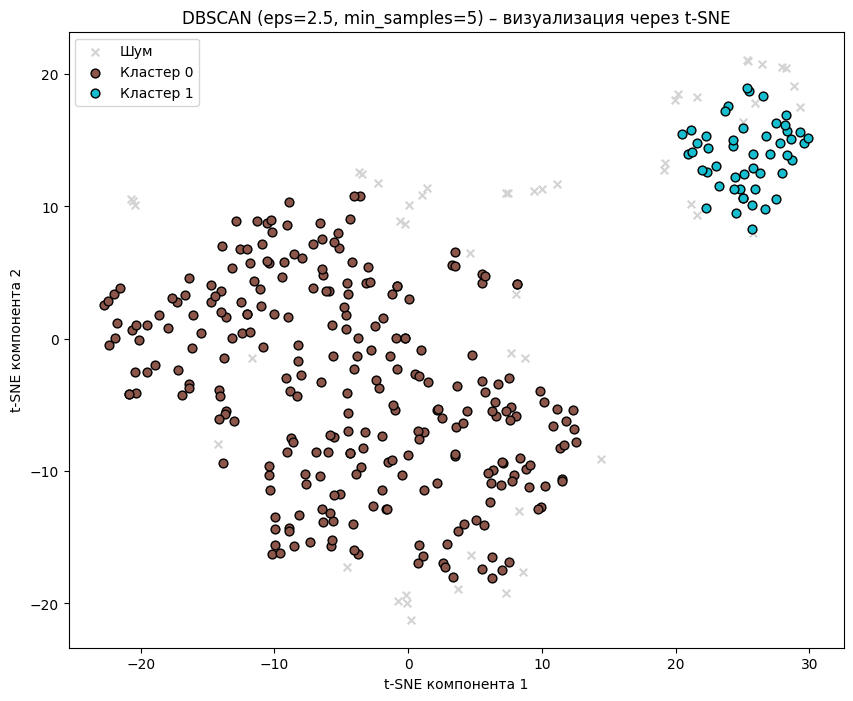

In [22]:
min_samples = 5
eps=2.5
tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_iter=1000)
X_tsne = tsne.fit_transform(X_train)   # проецируем 8‑мерные данные в 2D

# Визуализируем результат DBSCAN на плоскости t‑SNE
plt.figure(figsize=(10, 8))
# Цветовая схема: шум (метка -1) – серый, остальные кластеры – разные цвета
unique_labels = np.unique(labels_db)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

for label, col in zip(unique_labels, colors):
    if label == -1:
        col = 'lightgray'
        marker = 'x'
        size = 30
        label_txt = 'Шум'
    else:
        marker = 'o'
        size = 40
        label_txt = f'Кластер {label}'

    plt.scatter(X_tsne[labels_db == label, 0], X_tsne[labels_db == label, 1],
                c=[col], marker=marker, s=size, label=label_txt, edgecolors='k')

plt.title(f'DBSCAN (eps={eps}, min_samples={min_samples}) – визуализация через t‑SNE')
plt.xlabel('t‑SNE компонента 1')
plt.ylabel('t‑SNE компонента 2')
plt.legend()
plt.show()

Мы действительно выделили некоторые 2 кластера. В дальнейшем, при обучении моделей, подумаем, как можно этим воспользоваться.

На этом наш разведочный анализ данных подошел к концу. Теперь попробуем подобрать модели, которые бы идеально подошли к нашей задаче

# Подбор моделей

Для начала попробуем многослойную нейронную сеть. Подберем для нее подходящие параметры -- dropout, размернрсть скрытого слоя -- hidden_dim, количество скрытых слоев сети -- num_layers


In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [24]:
# device = torch.device('cpu')
# device

In [25]:
X_train.shape


(359, 14)

In [26]:
class Perceptron(torch.nn.Module):
    @property
    def device(self):
        for p in self.parameters():
            return p.device

    def __init__(self, input_dim = 14, num_layers=0,
                 hidden_dim=64, output_dim=1, p=0.0):
        super(Perceptron, self).__init__()

        self.layers = torch.nn.Sequential()

        prev_size = input_dim
        for i in range(num_layers):
            self.layers.add_module('layer{}'.format(i),
                                  torch.nn.Linear(prev_size, hidden_dim, bias = True))
            self.layers.add_module('relu{}'.format(i), torch.nn.ReLU())
            self.layers.add_module('dropout{}'.format(i), torch.nn.Dropout(p=p))
            prev_size = hidden_dim

        self.layers.add_module('regressor',
                               torch.nn.Linear(prev_size, output_dim))

    def forward(self, input):
        return self.layers(input)

In [27]:
def testing(model, dataset):
    generator = torch.utils.data.DataLoader(dataset, batch_size=64)

    pred = []
    real = []
    for x, y in generator:
        x = x.to(device)
        y = y.to(device)

        pred.extend(model(x).detach().cpu().numpy().tolist())
        real.extend(y.cpu().numpy().tolist())
    r2 = r2_score(real, pred)
    return r2

In [28]:
def trainer(model, dataset, loss_function, optimizer, epochs):
    for epoch in tqdm(range(epochs), leave=False):
        generator = torch.utils.data.DataLoader(dataset, batch_size=64,
                                                shuffle=True)
        for x, y in tqdm(generator, leave=False):
            optimizer.zero_grad()
            x = x.to(device)
            y = y.to(device)

            output = model(x)
            loss = loss_function(output, y)
            loss.backward()
            optimizer.step()

In [29]:
cross_val = KFold(n_splits = 8, shuffle=True, random_state=42)
number_of_batch = cross_val.get_n_splits(X_train)
grid = ParameterGrid({'num_layers': [5, 10],
                      'hidden_dim': [8, 64],
                      'p': [0.3, 0.5],
                      'lr': [0.01]})


In [30]:
def draw_table(data, title=['R^2'], width=[60, 11]):
    row_format = '|' + '|'.join([("{:>"+str(w)+"}") for w in width]) + '|'
    row_format_bet = '+' + '+'.join([("{:>"+str(w)+"}") for w in width]) + '+'

    print(row_format_bet.format(
        "-"*width[0], *["-"*width[i+1] for i, _ in enumerate(title)]))
    print(row_format.format("", *title))
    print(row_format_bet.format(
        "-"*width[0], *["-"*width[i+1] for i, _ in enumerate(title)]))
    for key in data:
        if len(key) > width[0]:
            row_name = '...' + key[len(key)-width[0]+3:]
        else:
            row_name = key
        print(row_format.format(row_name, *[round(x, 2) for x in data[key]]))
        print(row_format_bet.format(
            "-"*width[0], *["-"*width[i+1] for i, _ in enumerate(title)]))

In [31]:
# import os
# os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

In [32]:
Y_train = y_train.to_numpy()
Y_test = y_test.to_numpy()

scores = dict()
for item in tqdm(grid, leave = False):

    list_of_scores = []
    for train_index, test_index in tqdm(cross_val.split(X_train),
                                        total=number_of_batch, leave=False):
        # Преобразование в тензоры
        X_train_t = torch.tensor(X_train[train_index], dtype=torch.float32)
        y_train_t = torch.tensor(Y_train[train_index], dtype=torch.float32)
        X_test_t = torch.tensor(X_train[test_index], dtype=torch.float32)
        y_test_t = torch.tensor(Y_train[test_index], dtype=torch.float32)


        train_dataset = TensorDataset(X_train_t, y_train_t)
        test_dataset = TensorDataset(X_test_t, y_test_t)

        model = Perceptron(num_layers=item['num_layers'], p=item['p'],
                           hidden_dim=item['hidden_dim'], output_dim =1)
        model.to(device)
        #print(model)
        _ = model.train()
        trainer(model=model,
                dataset=train_dataset,
                loss_function=torch.nn.MSELoss(),
                optimizer=torch.optim.Adam(model.parameters(), lr=item['lr']),
                epochs=5)

        _ = model.eval()
        rmse = testing(model, test_dataset)
        #print(rmse)
        list_of_scores.append(rmse)
    scores[str(item)] = [np.mean(list_of_scores)]



  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

... (383 outputs left out)

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

In [33]:
draw_table(scores)

+------------------------------------------------------------+-----------+
|                                                            |        R^2|
+------------------------------------------------------------+-----------+
|    {'hidden_dim': 8, 'lr': 0.01, 'num_layers': 5, 'p': 0.3}|       -0.1|
+------------------------------------------------------------+-----------+
|    {'hidden_dim': 8, 'lr': 0.01, 'num_layers': 5, 'p': 0.5}|      -0.13|
+------------------------------------------------------------+-----------+
|   {'hidden_dim': 8, 'lr': 0.01, 'num_layers': 10, 'p': 0.3}|      -0.08|
+------------------------------------------------------------+-----------+
|   {'hidden_dim': 8, 'lr': 0.01, 'num_layers': 10, 'p': 0.5}|      -0.07|
+------------------------------------------------------------+-----------+
|   {'hidden_dim': 64, 'lr': 0.01, 'num_layers': 5, 'p': 0.3}|      -0.14|
+------------------------------------------------------------+-----------+
|   {'hidden_dim': 64, 'l

Пока что самая перспективная модель -- {'hidden_dim': 8, 'lr': 0.01, 'num_layers': 10, 'p': 0.3}. Попробуем увеличить количество эпох обучения, чтобы добиться лучшего качества

In [34]:
Y_train = y_train.to_numpy()
Y_test = y_test.to_numpy()
list_of_scores = []


model = Perceptron(num_layers=10, p=0.3,
                          hidden_dim=8)
model.to(device)
#print(device)
for train_index, test_index in tqdm(cross_val.split(X_train),
                                        total=number_of_batch, leave=False):
      # Преобразование в тензоры
      X_train_t = torch.tensor(X_train[train_index], dtype=torch.float32)
      y_train_t = torch.tensor(Y_train[train_index], dtype=torch.float32)
      X_test_t = torch.tensor(X_train[test_index], dtype=torch.float32)
      y_test_t = torch.tensor(Y_train[test_index], dtype=torch.float32)


      train_dataset = TensorDataset(X_train_t, y_train_t)
      test_dataset = TensorDataset(X_test_t, y_test_t)

      #print(model)
      _ = model.train()
      trainer(model=model,
              dataset=train_dataset,
              loss_function=torch.nn.MSELoss(),
              optimizer=torch.optim.Adam(model.parameters(), lr=0.01),
              epochs=20)
      _ = model.eval()
      #print(model)
      rmse = testing(model, test_dataset)
      #print(rmse)
      list_of_scores.append(rmse)


  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

... (159 outputs left out)

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

In [35]:
np.mean(list_of_scores)

np.float64(-0.1390243629259155)

Модель уже явно начинает переобучаться и давать нежелательный результат. Попробуем перейти к другим моделям, так как нейросеть не подходит для данной задачи.

Протестируем разные бустинги. Для начала попробуем оставить категориальные признаки, так как такие модели как XGBoost, LightGBM, CatBoost умеют с ними работать, потом попробуем оставить нашу циклическую замену.

In [36]:
mapping = {'jan': 0, 'feb' : 1, 'mar' : 2, 'apr' : 3, 'may' : 4, 'jun' : 5,
           'jul' : 6, 'aug' : 7, 'sep' : 8, 'oct' :9, 'nov' : 10, 'dec' : 11}
ser = (dataset['month'].map(mapping))
dataset['month'] = ser
mapping = {'mon':0, 'tue':1, 'wed':2, 'thu':3, 'fri' :4, 'sat':5, 'sun':6}
ser = dataset['day'].map(mapping)
dataset['day'] = ser

In [37]:
dataset['month'] = dataset['month'].astype('int')
dataset['day'] = dataset['day'].astype('int')


In [38]:
dataset = dataset[dataset['area'] <=300]
dataset = dataset[dataset['rain'] <=3]

In [39]:
X_df = dataset.iloc[:, :-1]
y_df = dataset.iloc[:, -1]
y_df

,area
0,0.00
1,0.00
2,0.00
3,0.00
4,0.00
...,...
512,6.44
513,54.29
514,11.16
515,0.00


In [40]:
X_train_df, X_test_df, y_train_df, y_test_df = train_test_split(X_df, y_df, test_size=0.3, shuffle=True, random_state=42)
X_train_df

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain
94,8,6,7,0,91.1,103.2,638.8,5.8,23.4,22,2.7,0.0
312,2,4,8,6,50.4,46.2,706.6,0.4,12.2,78,6.3,0.0
368,6,5,8,5,91.2,94.3,744.4,8.4,16.8,47,4.9,0.0
23,7,4,7,5,90.2,110.9,537.4,6.2,19.5,43,5.8,0.0
272,2,5,7,1,92.1,152.6,658.2,14.3,20.2,47,4.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
106,4,5,2,3,91.4,30.7,74.3,7.5,18.2,29,3.1,0.0
271,8,6,7,1,92.1,152.6,658.2,14.3,20.1,58,4.5,0.0
349,5,4,8,4,92.1,99.0,745.3,9.6,12.8,64,3.6,0.0
437,8,6,7,5,89.4,253.6,768.4,9.7,14.2,73,2.7,0.0


In [41]:
print(X_train_df[['month', 'day']].dtypes)


month    int64
day      int64
dtype: object


In [42]:
cat_indices = [2,3]

In [43]:
print('Среднее y_train:', y_train_df.mean())
print('Среднее y_test:', y_test_df.mean())
print('Дисперсия y_train:', y_train_df.var())
print('Дисперсия y_test:', y_test_df.var())


Среднее y_train: 10.019972144846797
Среднее y_test: 7.722193548387097
Дисперсия y_train: 852.0624092170997
Дисперсия y_test: 512.2680250272293


In [44]:
model_lgb = lgb.LGBMRegressor(
    verbose=-1,
    categorical_feature=cat_indices,
    n_estimators=10,
    learning_rate=0.01,
    max_depth=2,
    num_leaves=5, # как сказано в интернете, нужно выбирать примерно как 2^max_depth, поэтому ~ так и сделаем
    subsample=1,
    colsample_bytree=1,
    random_state=42
)
scores = cross_val_score(model_lgb, X_train_df, y_train_df, cv=5,
                         scoring='r2')
print(np.mean(scores))

-0.03882553840924348


In [45]:
from sklearn.dummy import DummyRegressor
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train_df, y_train_df)
print('R² Dummy:', r2_score(y_test_df, dummy.predict(X_test_df)))

R² Dummy: -0.010373614097517248


In [46]:
model_lgb = lgb.LGBMRegressor(
    verbose=-1,
    n_estimators=10,
    learning_rate=0.01,
    max_depth=2,
    num_leaves=5, # как сказано в интернете, нужно выбирать примерно как 2^max_depth, поэтому ~ так и сделаем
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)
scores = cross_val_score(model_lgb, X_train, y_train, cv=5,
                         scoring='r2')
print(np.mean(scores))

-0.039523992448318966


In [47]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred_test = model.predict(X_test)

print(f"R^2: {r2_score(y_test, y_pred_test):.4f}")
# print(f"MAE: {mean_absolute_error(y_train, y_pred_train):.4f}")
# print(f"RMSE: {np.sqrt(mean_squared_error(y_train, y_pred_train)):.4f}")

y_pred_train = model.predict(X_train)

print(f"R^2: {r2_score(y_train, y_pred_train):.4f}")

R^2: -0.0279
R^2: 0.0415


In [48]:
ridge = Ridge(alpha=5)
ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)
print(f"Ridge R^2: {r2_score(y_test, ridge_pred):.2f}")


Ridge R^2: -0.03


In [49]:
lasso = Lasso(alpha=0.1)
lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)
print(f"Lasso R^2: {r2_score(y_test, lasso_pred):.2f}")

Lasso R^2: -0.03


In [50]:
svr = SVR(kernel='rbf', C=1.0, epsilon=0.1)
svr.fit(X_train, y_train)
y_pred_svr = svr.predict(X_test)

print(f"R^2 in SVR: {r2_score(y_test, y_pred_svr):.4f}")

R^2 in SVR: -0.0852


In [51]:
from sklearn.neighbors import KNeighborsRegressor
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
knn = KNeighborsRegressor(n_neighbors=40, weights='distance')
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)


print(f"R^2: {r2_score(y_test, y_pred):.4f}")

R^2: -0.0439


In [52]:
correlations = [X[col].corr(y) for col in X.columns if X[col].dtype in ['float64', 'int64']]
print("Максимальная корреляция признака с y:", max(correlations))

Максимальная корреляция признака с y: 0.06866325982043044


На этом моменте все становится понятно окончательно. у нас есть большие проблемы с данными. В самой библиотеке UCI сказано, что это сложная задача регрессии. У нас проблема следующая -- низкая корреляция между признаками и целевой переменной в задаче -- максимум по датасету около 0.06. Более того, у нас в dataset большое количество нулевых и околонулевых данных, при этом если значение больше нуля, то они сильно больше нуля. Это приводит к тому, что выучить такую закономерность модели сложно. Поэтому нужно допреобразовать признаки, чтобы получить желаемый результат.

Прологорифмируем y, добавив к аргументу +1

In [53]:
# y_train = np.log1p(y_train)
# y_test = np.log1p(y_test)
# y_train

Теперь реализуем двухтапный подход: будем предсказывать случится ли пожар в целом, а потом для модели, для которых предсказано, что пожар будет, будем уже делать предсказание о площади возгорания

In [54]:
y_train_clf = (y_train > 0).astype(int)
y_test_clf = (y_test > 0).astype(int)

In [55]:
model_lgb_class = lgb.LGBMClassifier(verbose=-1,
                    categorical_feature=cat_indices,
                    n_estimators=10,
                    learning_rate=0.01,
                    max_depth=3,
                    num_leaves=7, # как сказано в интернете, нужно выбирать примерно как 2^max_depth, поэтому ~ так и сделаем
                    subsample=0.8,
                    colsample_bytree=0.8,
                    random_state=42)
model_lgb_class.fit(X_train_df,y_train_clf)

LGBMClassifier(categorical_feature=[2, 3], colsample_bytree=0.8,
               learning_rate=0.01, max_depth=3, n_estimators=10, num_leaves=7,
               random_state=42, subsample=0.8, verbose=-1)

In [56]:
y_pred_clf = model_lgb_class.predict(X_test_df)

print(f"f1_score: {f1_score(y_test_clf, y_pred_clf):.4f}")

f1_score: 0.6344


In [57]:
train_fire_mask = (y_train > 0)
test_fire_mask = (y_test > 0)

X_train_fire = X_train_df[train_fire_mask]
y_train_fire = y_train_df[train_fire_mask]
y_train_fire_log = np.log1p(y_train_fire)


reg = lgb.LGBMRegressor( categorical_feature=cat_indices,
                       n_estimators=15, random_state=42,
                       colsample_bytree = 0.8,
                       max_depth = 3,
                       max_leaves = 8)
reg.fit(X_train_fire, y_train_fire_log)

LGBMRegressor(categorical_feature=[2, 3], colsample_bytree=0.8, max_depth=3,
              max_leaves=8, n_estimators=15, random_state=42)

In [58]:
y_pred_proba = model_lgb_class.predict_proba(X_test_df)[:, 1]  # вероятность класса 1

threshold = 0.5

y_pred_final = np.zeros(len(X_test_df))

# Для объектов, где вероятность >= порога, делаем предсказание регрессором
mask_positive = y_pred_proba >= threshold
if mask_positive.any():
    # Предсказание в логарифмическом масштабе
    y_pred_final = reg.predict(X_test_df[mask_positive])
    # Возвращаем к исходным единицам
    #y_pred_final[mask_positive] = np.expm1(y_pred_log)

# Объектам с вероятностью < порога оставляем 0

# Оцениваем финальный R² (на исходной шкале)
r2 = r2_score(y_test, y_pred_final)
print(f"R^2: {r2:.4f}")


R^2: -0.0612


Результат все равно неутешительный. Что поделать, будем работать дальше.

Видимо, то что нам нужно -- преобразовать признаки. Вот этим и займемся. Для начала, вернемся к исходному датасету и применим преоьразования sin или log для разных признаков.

In [59]:
dataset

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,2,4,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.00
1,7,4,9,1,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.00
2,7,4,9,5,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.00
3,8,6,2,4,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.00
4,8,6,2,6,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
512,4,3,7,6,81.6,56.7,665.6,1.9,27.8,32,2.7,0.0,6.44
513,2,4,7,6,81.6,56.7,665.6,1.9,21.9,71,5.8,0.0,54.29
514,7,4,7,6,81.6,56.7,665.6,1.9,21.2,70,6.7,0.0,11.16
515,1,4,7,5,94.4,146.0,614.7,11.3,25.6,42,4.0,0.0,0.00


In [60]:
class Evaluate_Model():
    def __init__(self, model, data):
        self.model = model
        self.data = data
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            data.drop(['log_area'], axis = 1), data['log_area'], random_state = 42)
    def cross_validate_model(self, cv):
        scores = cross_val_score(model, self.data.drop(columns = ['log_area']), self.data['log_area'], cv = cv)
        print(f'max R2 score: {np.max(scores): .6f}')
        print(f'mean R2 score: {np.mean(scores): .6f}')
        print(f'min R2 score: {np.min(scores): .6f}')
    def evaluate_model(self):
        self.model.fit(self.X_train, self.y_train)
        train_preds = model.predict(self.X_train)
        test_preds = model.predict(self.X_test)
        print(f'R2 score on training set: {r2_score(self.y_train, train_preds): .6f}')
        print(f'R2 score on  testing set: {r2_score(self.y_test, test_preds): .6f}')

In [61]:
sin_month = [math.sin(x) for x in dataset['month']]
sin_day = [math.sin(x) for x in dataset['day']]
log_ffmc = [math.log(x+1) for x in dataset['FFMC']]
log_dc = [math.log(x+1) for x in dataset['DC']]
log_isi = [math.log(x+1) for x in dataset['ISI']]
log_area = [math.log(x+1) for x in dataset['area']]
log_rh = [math.log(x+1) for x in dataset['RH']]
log_rain = [math.log(x+1) for x in dataset['rain']]


In [62]:
dataset['sin_month'] = sin_month
dataset['sin_day'] = sin_day
dataset['log_ffmc'] = log_ffmc
dataset['log_dc'] = log_dc




In [63]:
dataset['log_isi'] = log_isi
dataset['log_area'] = log_area
dataset['log_rh'] = log_rh
dataset['log_rain'] = log_rain


In [64]:
dataset.drop(['month', 'day', 'DC', 'ISI', 'RH', 'rain', 'area', 'FFMC'], axis=1, inplace=True)


In [65]:
dataset

,X,Y,DMC,temp,wind,sin_month,sin_day,log_ffmc,log_dc,log_isi,log_area,log_rh,log_rain
0,7,5,26.2,8.2,6.7,0.909297,-0.756802,4.468204,4.557030,1.808289,0.000000,3.951244,0.000000
1,7,4,35.4,18.0,0.9,0.412118,0.841471,4.517431,6.507427,2.041220,0.000000,3.526361,0.000000
2,7,4,43.7,14.6,1.3,0.412118,-0.958924,4.517431,6.533643,2.041220,0.000000,3.526361,0.000000
3,8,6,33.3,8.3,4.0,0.909297,-0.756802,4.529368,4.363099,2.302585,0.000000,4.584967,0.182322
4,8,6,51.3,11.4,1.8,0.909297,-0.279415,4.503137,4.636669,2.360854,0.000000,4.605170,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
512,4,3,56.7,27.8,2.7,0.656987,-0.279415,4.414010,6.502190,1.064711,2.006871,3.496508,0.000000
513,2,4,56.7,21.9,5.8,0.656987,-0.279415,4.414010,6.502190,1.064711,4.012592,4.276666,0.000000
514,7,4,56.7,21.2,6.7,0.656987,-0.279415,4.414010,6.502190,1.064711,2.498152,4.262680,0.000000
515,1,4,146.0,25.6,4.0,0.656987,-0.958924,4.558079,6.422760,2.509599,0.000000,3.761200,0.000000


In [66]:
models = [RandomForestRegressor(n_estimators = 6, random_state=42, max_depth = 3, bootstrap =True), lgb.LGBMRegressor(n_estimators=6, random_state=42,
                       colsample_bytree = 0.8,
                       max_depth = 3,
                       max_leaves = 8),
          xgb.XGBRegressor(n_estimators=8, random_state=42,
                       colsample_bytree = 0.6,
                       max_depth = 2,
                       max_leaves = 5),
          ExtraTreesRegressor(bootstrap=True,
                              n_estimators = 15,
                              max_depth =3),
          SVR(kernel='rbf', C=2.0, epsilon=0.05)]

In [67]:
print('Cross Validating Models\n')
for model in models:
    print(type(model).__name__)
    modeling = Evaluate_Model(model, dataset)
    modeling.cross_validate_model(10)
    print()

Cross Validating Models

RandomForestRegressor
max R2 score:  0.008399
mean R2 score: -1.170032
min R2 score: -6.364624

LGBMRegressor
max R2 score:  0.000000
mean R2 score: -1.188717
min R2 score: -8.128006

XGBRegressor
max R2 score:  0.016220
mean R2 score: -1.316117
min R2 score: -8.218852

ExtraTreesRegressor
max R2 score:  0.000000
mean R2 score: -1.202809
min R2 score: -7.997873

SVR
max R2 score:  0.000000
mean R2 score: -1.395755
min R2 score: -8.195727



Как показал дополнительный ресерч, модели Deep Learning не дают увеличение r2_score. Они показывают такой же околонулевой результат для данной метрики.  

# Выводы

Был проведен разведочный анализ данных. В ходе него были выявлены закономерности в данных, удаление выбросов. Для разных моделей были испробованы разные преобразования признаков, которые могли привести к снижению переобучения и повышению эффективности обучения, а именно, проводилась борьба с дисперсией в данных.

Были испробованы самые разные модели, подбирались гиперпараметры.  
Ключевыми моделями можно назвать:
LightGBM, XGBoost, RandomForest, Многослойная нейронная сеть и другие (всего около 10 моделей).

Задачей было максимизировать метрику $R^2$. В силу того, что данных в целом не так много, а также тем, что зависимости между признаками и целевой переменной едва уловимы отличным результатом можно счиатать выход на положительный $R^2$ для XGBRegressor.

В ходе исслелования также применялся подход двухуровневой регрессии. А именно, изначально решалась задача классификации -- будет пожар или нет. В случае, если модель предсказывала пожар, то мы переходили на 2-ой уровень -- предсказание площади возгорания. Но и такой подход не увенчался успехом.

Преобразование Yeo-Johnson над таргетом также не дало видимых результатов.

Была проведена огромная работа, задача действительно является очень трудной, малое количество наблюдений и прочие причины не позволяют построить модель очень высокого качества. Однако, даже те модели, для которых были в итоге получены неотрицательные результаты по метрике $R^2$, являются больщим достижением в условиях данной задачи.  

In [68]:
import subprocess

subprocess.run(['jupyter', 'nbconvert','/content/drive/MyDrive/Colab Notebooks/forest_fires.ipynb' , '--to', 'html'])

CompletedProcess(args=['jupyter', 'nbconvert', '/content/drive/MyDrive/Colab Notebooks/forest_fires.ipynb', '--to', 'html'], returncode=0)

In [69]:
import json, os
from google.colab import files

src = '/content/drive/MyDrive/Colab Notebooks/forest_fires.ipynb'


with open(src) as f:
    nb = json.load(f)

# Убираем сломанные metadata виджетов
nb.get('metadata', {}).pop('widgets', None)
for cell in nb.get('cells', []):
    cell.get('metadata', {}).pop('widgets', None)

out = '/content/drive/MyDrive/Colab Notebooks/forest_fires.ipynb'
with open(out, 'w') as f:
    json.dump(nb, f, indent=1)

files.download(out)
print('Готово. Файл скачается автоматически.')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Готово. Файл скачается автоматически.


Конец